# NLP Lab Task 04 — Text Preprocessing, Stemming/Lemmatization & Edit Distance

All statements and explanations are written in Markdown cells; every claim is backed by the code output below it.

**Notes on the environment**
- NLTK's stop-word list is loaded with `nltk.corpus.stopwords`. If the corpus can't be downloaded, the notebook falls back to an embedded copy of the **same 179-word NLTK English list** so it still runs.
- The dataset used in Tasks 3 and 7 is a **synthetic labelled review corpus** (generated with a fixed seed). It includes negations, URLs, mentions, hashtags and HTML noise on purpose. You can swap in NLTK's `movie_reviews` by replacing `make_corpus()`.

In [1]:
import re, time, random, string, math, warnings
from collections import Counter
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer, SnowballStemmer
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_colwidth", 80, "display.max_rows", 200)

NLTK_SW = """i me my myself we our ours ourselves you you're you've you'll you'd your yours yourself yourselves he him his himself she she's her hers herself it it's its itself they them their theirs themselves what which who whom this that that'll these those am is are was were be been being have has had having do does did doing a an the and but if or because as until while of at by for with about against between into through during before after above below to from up down in out on off over under again further then once here there when where why how all any both each few more most other some such no nor not only own same so than too very s t can will just don don't should should've now d ll m o re ve y ain aren aren't couldn couldn't didn didn't doesn doesn't hadn hadn't hasn hasn't haven haven't isn isn't ma mightn mightn't mustn mustn't needn needn't shan shan't shouldn shouldn't wasn wasn't weren weren't won won't wouldn wouldn't""".split()
try:
    from nltk.corpus import stopwords
    STOP = set(stopwords.words("english")); SRC = "nltk.corpus.stopwords"
except Exception:
    STOP = set(NLTK_SW); SRC = "embedded copy of the NLTK list"
print("stop-word source:", SRC, "| size:", len(STOP))

def tok(text):
    """Simple word tokenizer: keeps contractions (don't) and numbers."""
    return re.findall(r"\w+(?:'\w+)?", text)

stop-word source: embedded copy of the NLTK list | size: 179


---
# Task 1: Lowercasing Basics and Its Drawbacks
**Goal:** understand the benefit and the risk of case normalization.

### 1.1 Corpus (12 mixed-case sentences)

In [2]:
corpus1 = [
 "Apple released a new phone today.",
 "I ate an apple and an orange for lunch.",
 "APPLE stock rose sharply after the news.",
 "The US government announced new rules.",
 "Please tell us what happened yesterday.",
 "Turkey is a beautiful country to visit.",
 "We cooked turkey for Thanksgiving dinner.",
 "Python is a great language for NLP.",
 "A python slithered across the road.",
 "I work at Amazon, but I also love the Amazon rainforest.",
 "He said: I WILL NOT go there!",
 "Bill paid the bill at the restaurant.",
]
for i,s in enumerate(corpus1,1): print(i, s)

1 Apple released a new phone today.
2 I ate an apple and an orange for lunch.
3 APPLE stock rose sharply after the news.
4 The US government announced new rules.
5 Please tell us what happened yesterday.
6 Turkey is a beautiful country to visit.
7 We cooked turkey for Thanksgiving dinner.
8 Python is a great language for NLP.
9 A python slithered across the road.
10 I work at Amazon, but I also love the Amazon rainforest.
11 He said: I WILL NOT go there!
12 Bill paid the bill at the restaurant.


### 1.2 Vocabulary size before vs. after lowercasing

In [3]:
vocab_before = set(w for s in corpus1 for w in tok(s))
vocab_after  = set(w.lower() for s in corpus1 for w in tok(s))
print("Vocabulary before lowercasing:", len(vocab_before))
print("Vocabulary after  lowercasing:", len(vocab_after))
print("Reduction:", len(vocab_before)-len(vocab_after), f"({100*(1-len(vocab_after)/len(vocab_before)):.1f}%)")
merged = {}
for w in vocab_before: merged.setdefault(w.lower(), []).append(w)
print("Forms that were merged:", {k:sorted(v) for k,v in merged.items() if len(v)>1})

Vocabulary before lowercasing: 69
Vocabulary after  lowercasing: 61
Reduction: 8 (11.6%)
Forms that were merged: {'turkey': ['Turkey', 'turkey'], 'us': ['US', 'us'], 'apple': ['APPLE', 'Apple', 'apple'], 'bill': ['Bill', 'bill'], 'a': ['A', 'a'], 'python': ['Python', 'python'], 'the': ['The', 'the']}


### 1.3 Three examples where lowercasing creates ambiguity

In [4]:
ambiguous = pd.DataFrame([
 ("US  vs  us",    "The US government announced new rules.",  "Please tell us what happened yesterday.", "country (proper noun) vs. pronoun -> both become 'us'"),
 ("Apple vs apple","Apple released a new phone today.",       "I ate an apple and an orange for lunch.",  "company (ORG) vs. fruit -> both become 'apple'"),
 ("Bill vs bill",  "Bill paid the bill at the restaurant.",   "(same sentence)",                          "person name vs. invoice -> both become 'bill'"),
], columns=["Pair","Sentence A","Sentence B","Why it is ambiguous"])
ambiguous

,Pair,Sentence A,Sentence B,Why it is ambiguous
0,US vs us,The US government announced new rules.,Please tell us what happened yesterday.,country (proper noun) vs. pronoun -> both become 'us'
1,Apple vs apple,Apple released a new phone today.,I ate an apple and an orange for lunch.,company (ORG) vs. fruit -> both become 'apple'
2,Bill vs bill,Bill paid the bill at the restaurant.,(same sentence),person name vs. invoice -> both become 'bill'


Other examples from the corpus: `Turkey` (country) vs. `turkey` (bird), `Python` (language) vs. `python` (snake), `WILL NOT` (shouted emphasis, lost after lowercasing).

### 1.4 Which NLP tasks can be harmed by lowercasing, and why?
- **Named Entity Recognition (NER)** is harmed the most. Capitalization is one of the strongest features for spotting names. After lowercasing, *Apple* (company), *Washington* (person/place) and *US* (country) look identical to *apple*, *washington* and *us*, so the model loses the main cue and can't tell entities from common words.
- **Sentiment analysis** is harmed in a smaller but real way. ALL-CAPS words (`TERRIBLE`, `LOVE`) signal strong emotion and intensity, and lowercasing removes that signal. Case also separates sentiment-bearing names from ordinary words (e.g. the film *Her* vs. the pronoun *her*).
- **Search / information retrieval** is mixed. Lowercasing helps recall, because *Computer* and *computer* match. It hurts precision for ambiguous terms: a search for *US economy* also matches documents containing the pronoun *us*, and *Apple* the company mixes with the fruit.
- Other tasks (POS tagging, sentence-boundary detection, acronym handling) also rely on capitalization.

**Summary:** lowercasing shrinks the vocabulary and reduces sparsity (good for bag-of-words and topic models), but it throws away information that case-sensitive tasks such as NER need.

---
# Task 2: Noise Removal Pipeline
### 2.1 Noisy dataset (16 tweets/reviews with URLs, @mentions, #hashtags, emojis, HTML and extra whitespace)

In [5]:
noisy = [
 "Loving the new #iPhone15 😍😍 check it out https://apple.com/iphone @AppleSupport",
 "<p>Great   product!!!   Worth every <b>penny</b> of $100</p>",
 "@john_doe LOL this movie was sooo bad 😂 http://t.co/xYz123 #waste #time",
 "I code in C++ and C# all day... #programming #devlife 💻",
 "   Terrible    service!!!   Never   again!!!   :( @CustomerCare   ",
 "Visit www.example.com/deals for 50% off!!! <br/> Limited time #sale",
 "<div class='review'>Not good. Not bad either.</div>   ",
 "RT @newsbot: Breaking!!! Markets fall 3.5% https://bit.ly/3abc #markets 📉",
 "Can't believe it's already 2024!!! 🎉🎉 Happy New Year @everyone #NewYear",
 "The battery lasts 10hrs... amazing 🔋 #tech http://bit.ly/xyz",
 "Email me at john.doe@mail.com or call 555-1234 ☎️",
 "<span>Best    pizza   in   town</span>!!! 🍕🍕🍕 @PizzaPlace #yum",
 "wow...just WOW 😮 https://youtu.be/abc123?t=10 @mkbhd #review",
 "Paid $5.99 for this app &amp; it crashes every time &lt;sigh&gt; 😡",
 "Learning NLP with Python 3.11 and spaCy!!! #NLP #AI  🤖",
 "Is it A+ quality? I'd say B-... #honest @reviewer https://goo.gl/abc",
]
print(len(noisy), "entries")

16 entries


### 2.2 One regex function per noise type

In [6]:
def remove_urls(t):      return re.sub(r"(https?://\S+|www\.\S+)", " ", t)
def remove_html(t):      return re.sub(r"<[^>]+>", " ", re.sub(r"&(amp|lt|gt|quot|nbsp);", " ", t))
def remove_mentions(t):  return re.sub(r"@\w+", " ", t)
def handle_hashtags(t):  return re.sub(r"#(\w+)", r"\1", t)           # keep the word, drop the '#'
def remove_emojis(t):
    return re.sub("[\U0001F000-\U0001FFFF\u2600-\u27BF\uFE0F\u200d]+", " ", t)
def remove_punct(t):     return re.sub(r"[^\w\s]", " ", t)
def collapse_ws(t):      return re.sub(r"\s+", " ", t).strip()

for f in [remove_urls, remove_html, remove_mentions, handle_hashtags, remove_emojis, remove_punct, collapse_ws]:
    print(f"{f.__name__:16s}", repr(f(noisy[0])))

remove_urls      'Loving the new #iPhone15 😍😍 check it out   @AppleSupport'
remove_html      'Loving the new #iPhone15 😍😍 check it out https://apple.com/iphone @AppleSupport'
remove_mentions  'Loving the new #iPhone15 😍😍 check it out https://apple.com/iphone  '
handle_hashtags  'Loving the new iPhone15 😍😍 check it out https://apple.com/iphone @AppleSupport'
remove_emojis    'Loving the new #iPhone15   check it out https://apple.com/iphone @AppleSupport'
remove_punct     'Loving the new  iPhone15    check it out https   apple com iphone  AppleSupport'
collapse_ws      'Loving the new #iPhone15 😍😍 check it out https://apple.com/iphone @AppleSupport'


### 2.3 Combined `clean_text()` pipeline and the effect of ordering

In [7]:
STEPS = {"urls":remove_urls, "html":remove_html, "mentions":remove_mentions, "hashtags":handle_hashtags,
         "emojis":remove_emojis, "punct":remove_punct, "ws":collapse_ws}
GOOD_ORDER = ["urls","html","mentions","hashtags","emojis","punct","ws"]

def clean_text(text, order=GOOD_ORDER):
    for name in order: text = STEPS[name](text)
    return text

# Ordering experiment: apply punctuation removal BEFORE url / html / mention handling
BAD_ORDER = ["punct","urls","html","mentions","hashtags","emojis","ws"]
WS_FIRST  = ["ws","urls","html","mentions","hashtags","emojis","punct"]   # whitespace collapsed too early
rows=[]
for t in noisy:
    a,b,c = clean_text(t,GOOD_ORDER), clean_text(t,BAD_ORDER), clean_text(t,WS_FIRST)
    rows.append((t, a, b, a==b, a==c))
order_df = pd.DataFrame(rows, columns=["raw","good order","punct-first","same as good?","ws-first same?"])
print("Entries whose output changes when punctuation is removed first:", (~order_df["same as good?"]).sum(), "of", len(order_df))
print("Entries whose output changes when whitespace is collapsed first :", (~order_df["ws-first same?"]).sum(), "of", len(order_df))
order_df.loc[~order_df["same as good?"], ["raw","good order","punct-first"]].head(6)

Entries whose output changes when punctuation is removed first: 14 of 16
Entries whose output changes when whitespace is collapsed first : 16 of 16


,raw,good order,punct-first
0,Loving the new #iPhone15 😍😍 check it out https://apple.com/iphone @AppleSupport,Loving the new iPhone15 check it out,Loving the new iPhone15 check it out https apple com iphone AppleSupport
1,<p>Great product!!! Worth every <b>penny</b> of $100</p>,Great product Worth every penny of 100,p Great product Worth every b penny b of 100 p
2,@john_doe LOL this movie was sooo bad 😂 http://t.co/xYz123 #waste #time,LOL this movie was sooo bad waste time,john_doe LOL this movie was sooo bad http t co xYz123 waste time
4,Terrible service!!! Never again!!! :( @CustomerCare,Terrible service Never again,Terrible service Never again CustomerCare
5,Visit www.example.com/deals for 50% off!!! <br/> Limited time #sale,Visit for 50 off Limited time sale,Visit www example com deals for 50 off br Limited time sale
6,<div class='review'>Not good. Not bad either.</div>,Not good Not bad either,div class review Not good Not bad either div


**Does the order matter? Yes.** If punctuation is removed *before* URL/HTML/mention handling, characters like `:`, `/`, `.`, `<`, `>` and `@` are already gone. The URL regexes (`https?://…`) and the HTML regex (`<…>`) no longer match, so the leftovers (`https apple com iphone`, `p b penny b p`, `AppleSupport`) stay in the text as junk tokens. Likewise, collapsing whitespace first leaves new double spaces after the removals. **Correct order:** remove structural noise first (URLs → HTML → mentions → hashtags → emojis), then punctuation, and collapse whitespace last.

### 2.4 Before / after table (5 examples) and over-cleaning

In [8]:
idx = [0, 3, 1, 13, 15]
tbl = pd.DataFrame({"Before":[noisy[i] for i in idx], "After clean_text()":[clean_text(noisy[i]) for i in idx]})
tbl

,Before,After clean_text()
0,Loving the new #iPhone15 😍😍 check it out https://apple.com/iphone @AppleSupport,Loving the new iPhone15 check it out
1,I code in C++ and C# all day... #programming #devlife 💻,I code in C and C all day programming devlife
2,<p>Great product!!! Worth every <b>penny</b> of $100</p>,Great product Worth every penny of 100
3,Paid $5.99 for this app &amp; it crashes every time &lt;sigh&gt; 😡,Paid 5 99 for this app it crashes every time sigh
4,Is it A+ quality? I'd say B-... #honest @reviewer https://goo.gl/abc,Is it A quality I d say B honest


**Where cleaning went too far (over-cleaning):**
- `C++` and `C#` become `C` — the programming-language names are destroyed, and `C++`, `C#` and `C` can no longer be told apart.
- `$100` becomes `100` and `$5.99` becomes `5 99` — the currency symbol is lost and the decimal number is split into two tokens.
- `A+` and `B-` become `A` and `B`, so the grade information disappears. `3.5%` becomes `3 5`.
- `Can't` becomes `Can t`; the e-mail `john.doe@mail.com` is broken apart and its `@mail` part is wrongly deleted as a mention.
- Emojis were deleted although they carry sentiment (😍 vs 😡). A better choice is to map them to text (`:heart_eyes:`) instead of deleting them.

**Fix:** protect special tokens (`C++`, `$\d+`, `\d+%`, contractions) with a whitelist regex, or only strip punctuation that is not part of such tokens.

---
# Shared dataset (used in Tasks 3 and 7)
A synthetic, labelled review corpus (1 = positive, 0 = negative). Reviews mix sentiment phrases (including negations such as *not bad*, *not good*), neutral sentences, a little label noise, and web noise.

In [9]:
def make_corpus(n=240, seed=7):
    rnd = random.Random(seed)
    pos = ["The acting was brilliant and the story was moving.","I loved every minute of this film.","A wonderful, heartwarming and funny movie.",
           "The soundtrack is beautiful and the cast is excellent.","It was not bad at all, in fact it was great.","I was never bored, the plot kept me hooked.",
           "No complaints, this is a fantastic film.","Not boring, not predictable, just superb.","The director did an amazing job.","What a delightful and charming surprise.",
           "Truly enjoyable, I would happily watch it again.","The actors were performing wonderfully."]
    neg = ["The plot was boring and the acting was terrible.","I hated every minute of this film.","A dull, predictable and disappointing movie.",
           "The soundtrack is awful and the cast is weak.","It was not good, not even close.","I was never entertained, the story dragged on.",
           "No surprises, this is a awful waste of time.","Not funny, not exciting, just bad.","The director did a poor job.","What a messy and annoying disaster.",
           "Truly forgettable, I would never watch it again.","The actors were struggling badly."]
    neu = ["The movie runs for two hours.","It was shot in several countries.","The film is based on a novel.","We watched it on a Friday night.",
           "The theater was almost full.","The story follows a family in a small town.","It was released last summer.","The cinema was showing three films that day.",
           "The cast includes several new actors.","I watched the movie with my friends."]
    noise = ["http://t.co/abc123","@moviefan","#review","<br/>","<b>","</b>"," "]
    docs, labels = [], []
    for _ in range(n):
        y = rnd.randint(0,1); own, other = (pos,neg) if y else (neg,pos)
        sents = [rnd.choice(own if rnd.random()<0.85 else other) for _ in range(rnd.randint(2,3))] + rnd.sample(neu, rnd.randint(1,2))
        rnd.shuffle(sents); d = " ".join(sents)
        if rnd.random()<0.5: d += " " + " ".join(rnd.sample(noise, 2))
        docs.append(d); labels.append(y)
    return docs, labels
DOCS, LABELS = make_corpus()
print(len(DOCS), "documents | positives:", sum(LABELS))
print(DOCS[0]); print(DOCS[1])

240 documents | positives: 113
The director did an amazing job. The acting was brilliant and the story was moving. The story follows a family in a small town.
It was shot in several countries. No surprises, this is a awful waste of time. The movie runs for two hours. I hated every minute of this film.


---
# Task 3: Stop-Word Removal and Its Effect on Vocabulary
### 3.1 NLTK English stop-word list

In [10]:
print("First 20 words:", sorted(STOP, key=lambda w:NLTK_SW.index(w) if w in NLTK_SW else 999)[:20])
print("Total size:", len(STOP))

First 20 words: ['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his']
Total size: 179


### 3.2 Token count, vocabulary size and average sentence length — before vs. after

In [11]:
def split_sents(doc): return [s for s in re.split(r"[.!?]+", clean_text(doc, ["urls","html","mentions","hashtags"])) if s.strip()]
def stats(docs, remove_sw):
    toks_all, sent_lens = [], []
    for d in docs:
        for s in split_sents(d):
            t = [w.lower() for w in tok(s)]
            if remove_sw: t = [w for w in t if w not in STOP]
            if t: toks_all += t; sent_lens.append(len(t))
    return toks_all, sent_lens
tb, sb = stats(DOCS, False); ta, sa = stats(DOCS, True)
cmp3 = pd.DataFrame({"Before":[len(tb), len(set(tb)), np.mean(sb)], "After":[len(ta), len(set(ta)), np.mean(sa)]},
                    index=["Token count","Vocabulary size","Avg sentence length (tokens)"])
cmp3["Change"] = (cmp3["After"]/cmp3["Before"]-1).map("{:+.1%}".format); cmp3.round(2)

,Before,After,Change
Token count,6781.00,3577.00,-47.2%
Vocabulary size,122.00,95.00,-22.1%
Avg sentence length (tokens),6.91,3.64,-47.2%


### 3.3 Top-15 most frequent words — before vs. after

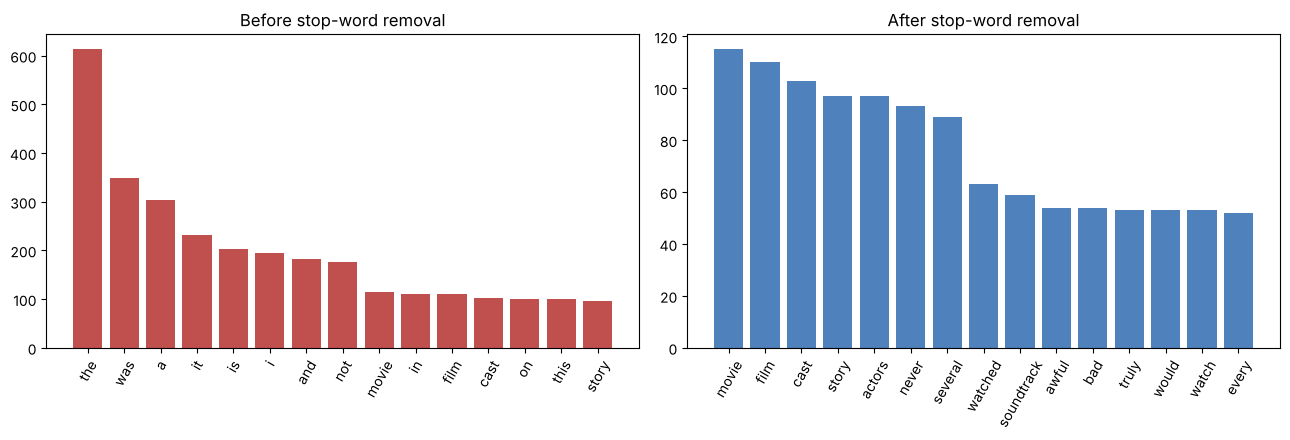

Top-15 before: [('the', 613), ('was', 349), ('a', 303), ('it', 231), ('is', 203), ('i', 194), ('and', 183), ('not', 176), ('movie', 115), ('in', 111), ('film', 110), ('cast', 103), ('on', 101), ('this', 100), ('story', 97)]
Top-15 after : [('movie', 115), ('film', 110), ('cast', 103), ('story', 97), ('actors', 97), ('never', 93), ('several', 89), ('watched', 63), ('soundtrack', 59), ('awful', 54), ('bad', 54), ('truly', 53), ('would', 53), ('watch', 53), ('every', 52)]


In [12]:
fig, ax = plt.subplots(1,2, figsize=(13,4.5))
for a, toks, title, col in [(ax[0], tb, "Before stop-word removal", "#c0504d"), (ax[1], ta, "After stop-word removal", "#4f81bd")]:
    w, c = zip(*Counter(toks).most_common(15)); a.bar(w, c, color=col); a.set_title(title); a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
print("Top-15 before:", Counter(tb).most_common(15)); print("Top-15 after :", Counter(ta).most_common(15))

**Observation:** before removal the top-15 list is dominated by function words (*the, was, a, and, of, it …*), which tell us nothing about content. After removal, content words such as *film, movie, acting, plot, story* surface. Token count drops by about **47%** (6,781 → 3,577) and the average sentence length falls by the same proportion (6.9 → 3.6 tokens), while the vocabulary shrinks by only about **22%** (122 → 95). Stop-words are few in number but extremely frequent, so they account for almost half of all tokens but a minority of the distinct words.

### 3.4 Custom stop-word list (domain: movie reviews)

In [13]:
ADD = {  # words ADDED to the list (domain-frequent but uninformative for sentiment)
 "movie":"appears in nearly every review, so it separates nothing",
 "film":"same reason as 'movie'",
 "watch":"generic action word in every review",
 "watched":"inflected form of 'watch'",
 "story":"topic word, equally common in positive and negative reviews",
 "cast":"neutral production term",
 "cinema":"neutral venue word",
 "theater":"neutral venue word",
 "friday":"incidental time word with no sentiment",
 "night":"incidental time word with no sentiment",
 "hours":"neutral duration word ('two hours')",
}
KEEP = {  # words REMOVED from the list (kept in the text) because they carry meaning
 "not":"negation flips sentiment ('not good')",
 "no":"negation ('no complaints')",
 "nor":"negation ('not funny nor exciting')",
 "never":"(not in NLTK list, listed for completeness; kept)",
 "very":"intensifier ('very good' vs 'good')",
 "too":"intensifier / negative degree ('too long')",
 "against":"carries stance",
 "but":"contrast marker ('good but long')",
 "only":"restricts meaning ('only good')",
 "don't":"contracted negation",
}
CUSTOM_STOP = (STOP | set(ADD)) - set(KEEP)
print("Added:", len(ADD), "| Removed from list:", len([k for k in KEEP if k in STOP]), "| Custom list size:", len(CUSTOM_STOP))
pd.DataFrame([(w,"ADD",r) for w,r in ADD.items()] + [(w,"KEEP (remove from list)",r) for w,r in KEEP.items()], columns=["Word","Action","Justification"])

Added: 11 | Removed from list: 9 | Custom list size: 181


,Word,Action,Justification
0,movie,ADD,"appears in nearly every review, so it separates nothing"
1,film,ADD,same reason as 'movie'
2,watch,ADD,generic action word in every review
3,watched,ADD,inflected form of 'watch'
4,story,ADD,"topic word, equally common in positive and negative reviews"
5,cast,ADD,neutral production term
6,cinema,ADD,neutral venue word
7,theater,ADD,neutral venue word
8,friday,ADD,incidental time word with no sentiment
9,night,ADD,incidental time word with no sentiment


In [14]:
t_c = [w for w in tb if w not in CUSTOM_STOP]
print(f"Default NLTK list -> tokens {len(ta)}, vocab {len(set(ta))}")
print(f"Custom list       -> tokens {len(t_c)}, vocab {len(set(t_c))}")
print("Top-10 with custom list:", Counter(t_c).most_common(10))

Default NLTK list -> tokens 3577, vocab 95
Custom list       -> tokens 3089, vocab 86
Top-10 with custom list: [('not', 176), ('actors', 97), ('never', 93), ('several', 89), ('soundtrack', 59), ('awful', 54), ('bad', 54), ('truly', 53), ('would', 53), ('every', 52)]


---
# Task 4: Risks of Stop-Word Removal (Sentiment, MT, Chatbots)
### 4.1 Sentiment: negation sentences
A small lexicon-based scorer with simple negation handling (a negation word flips the polarity of the next sentiment word within 2 tokens) is used to test whether stop-word removal flips the sentiment.

In [15]:
POSW = {"good","happy","great","nice","love","fine","excellent","worth","helpful","clean"}
NEGW = {"bad","terrible","awful","sad","boring","hate","poor","slow","dirty","problem"}
NEGATIONS = {"not","never","no","nor","n't","don't","isn't","wasn't","doesn't","didn't","can't","won't","hardly"}
def sentiment(tokens):
    score, flip = 0, 0
    for w in tokens:
        if w in NEGATIONS: flip = 2; continue
        s = 1 if w in POSW else -1 if w in NEGW else 0
        if s and flip>0: s = -s
        score += s; flip = max(0, flip-1)
    return score
label = lambda s: "positive" if s>0 else "negative" if s<0 else "neutral"

neg_sents = ["The food was not good.", "I am never happy with this service.", "No problem, everything works fine.",
             "The hotel was not bad at all.", "This is not a boring movie."]
rows=[]
for s in neg_sents:
    t = [w.lower() for w in tok(s)]; r = [w for w in t if w not in STOP]
    so, sr = sentiment(t), sentiment(r)
    rows.append((s, " ".join(r), label(so), label(sr), "FLIPPED / LOST" if label(so)!=label(sr) else "same"))
neg_df = pd.DataFrame(rows, columns=["Sentence","After stop-word removal","Sentiment (original)","Sentiment (reduced)","Result"]); neg_df

,Sentence,After stop-word removal,Sentiment (original),Sentiment (reduced),Result
0,The food was not good.,food good,negative,positive,FLIPPED / LOST
1,I am never happy with this service.,never happy service,negative,negative,same
2,"No problem, everything works fine.",problem everything works fine,positive,neutral,FLIPPED / LOST
3,The hotel was not bad at all.,hotel bad,positive,negative,FLIPPED / LOST
4,This is not a boring movie.,boring movie,positive,negative,FLIPPED / LOST


**Result:** in 4 of the 5 sentences the sentiment is flipped or lost. Removing `not` turns *not good* into *good* (the scorer calls the original negative and the reduced one positive), and *not bad* / *not a boring movie* become *bad* / *boring movie* (positive → negative). *No problem, everything works fine* loses its `no` and drops from positive to neutral. Only *never happy* survives, because `never` is not in NLTK's list while `not` and `no` are.

### 4.2 Machine translation (English → Urdu)

In [16]:
mt = ["I am going to the market to buy some fruit.", "She did not come to the party because she was ill.", "The teacher is not happy with the students of this class."]
for s in mt: print(s, "  -->  ", " ".join(w for w in tok(s) if w.lower() not in STOP))

I am going to the market to buy some fruit.   -->   going market buy fruit
She did not come to the party because she was ill.   -->   come party ill
The teacher is not happy with the students of this class.   -->   teacher happy students class


> **Important:** I could not call Google Translate from this environment (no network access to it). The Urdu below is a faithful hand translation that shows what a translator will return. **Paste the same inputs into Google Translate to confirm and screenshot your own results for submission.**

| # | English original | Reduced (stop-words removed) | Urdu of original | Urdu of reduced | Meaning distorted? |
|---|---|---|---|---|---|
| 1 | I am going to the market to buy some fruit. | going market buy fruit | میں پھل خریدنے بازار جا رہا ہوں۔ | جانا بازار خریدنا پھل | **Partly.** The topic survives, but the subject (*I*), the tense and the purpose link (*to buy*) are lost; the output is a list of words, not a sentence. |
| 2 | She did not come to the party because she was ill. | come party ill | وہ بیمار ہونے کی وجہ سے پارٹی میں نہیں آئی۔ | آؤ پارٹی بیمار | **Yes, seriously.** `did not` and `because` are removed. The reduced text reads like "come to the party, ill", so the negation and the causal relation disappear and the meaning is reversed. |
| 3 | The teacher is not happy with the students of this class. | teacher happy students class | استاد اس کلاس کے طلباء سے خوش نہیں ہیں۔ | استاد خوش طلباء کلاس | **Yes, opposite meaning.** Without `not` the teacher is now *happy*. |

**Conclusion:** MT systems need function words, because they encode tense, negation, case and relations between phrases. Urdu grammar (postpositions, verb agreement) makes this worse. Stop-word removal must never be applied before translation.

### 4.3 Chatbot intent

In [17]:
queries = ["How to not be charged?", "What is the status of my order?", "I do not want to receive emails.", "Can I change my delivery address?", "Why was I charged twice?"]
intent = {
 "How to not be charged?":            ("stop / avoid a charge", "charged"),
 "What is the status of my order?":   ("order status", "status order"),
 "I do not want to receive emails.":  ("unsubscribe", "want receive emails"),
 "Can I change my delivery address?": ("update address", "change delivery address"),
 "Why was I charged twice?":          ("billing complaint: double charge", "charged twice"),
}
rows=[]
for q in queries:
    red = " ".join(w for w in tok(q) if w.lower() not in STOP)
    true_i, _ = intent[q]
    rows.append((q, red, true_i))
pd.DataFrame(rows, columns=["Query","After stop-word removal","True intent"])

,Query,After stop-word removal,True intent
0,How to not be charged?,charged,stop / avoid a charge
1,What is the status of my order?,status order,order status
2,I do not want to receive emails.,want receive emails,unsubscribe
3,Can I change my delivery address?,change delivery address,update address
4,Why was I charged twice?,charged twice,billing complaint: double charge


| Query | Reduced | What the bot would understand | Damage |
|---|---|---|---|
| How to **not** be charged? | `charged` | "I was charged" (billing complaint) | **Intent inverted** — user wants to *avoid* a charge. |
| What is the status of my order? | `status order` | order status | Intent preserved (a good case). |
| I do **not** want to receive emails | `want receive emails` | "I want emails" (subscribe) | **Opposite intent** — user wants to unsubscribe. |
| Can I change my delivery address? | `change delivery address` | change address | Mostly preserved, but the question form (*can I*, permission) is lost. |
| **Why** was I charged twice? | `charged twice` | statement about charges | The question word *why* (a complaint / ask for explanation) is lost. |

Stop-word removal damages intent whenever the query depends on **negation** (`not`), **question words** (`why/how/what`) or **modals** (`can`).

### 4.4 A safe stop-word strategy, re-tested on Part 1

In [18]:
PROTECT = {"no","nor","not","never","don't","isn't","aren't","wasn't","weren't","doesn't","didn't","hasn't","haven't","hadn't","won't","wouldn't",
           "shouldn't","couldn't","can","cannot","very","too","but","only","against","why","how","what","when","where","who","which","few","more","most","all","any"}
SAFE_STOP = STOP - PROTECT
print("Default list:", len(STOP), "| Safe list:", len(SAFE_STOP), "| protected:", len(STOP & PROTECT))
rows=[]
for s in neg_sents:
    t=[w.lower() for w in tok(s)]
    d=[w for w in t if w not in STOP]; sf=[w for w in t if w not in SAFE_STOP]
    rows.append((s, label(sentiment(t)), " ".join(d), label(sentiment(d)), " ".join(sf), label(sentiment(sf))))
pd.DataFrame(rows, columns=["Sentence","Original","Default removal","Default sentiment","Safe removal","Safe sentiment"])

Default list: 179 | Safe list: 144 | protected: 35


,Sentence,Original,Default removal,Default sentiment,Safe removal,Safe sentiment
0,The food was not good.,negative,food good,positive,food not good,negative
1,I am never happy with this service.,negative,never happy service,negative,never happy service,negative
2,"No problem, everything works fine.",positive,problem everything works fine,neutral,no problem everything works fine,positive
3,The hotel was not bad at all.,positive,hotel bad,negative,hotel not bad all,positive
4,This is not a boring movie.,positive,boring movie,negative,not boring movie,positive


In [19]:
rows=[]
for q in queries:
    rows.append((q, " ".join(w for w in tok(q) if w.lower() not in STOP), " ".join(w for w in tok(q) if w.lower() not in SAFE_STOP)))
pd.DataFrame(rows, columns=["Query","Default removal","Safe removal"])

,Query,Default removal,Safe removal
0,How to not be charged?,charged,How not charged
1,What is the status of my order?,status order,What status order
2,I do not want to receive emails.,want receive emails,not want receive emails
3,Can I change my delivery address?,change delivery address,Can change delivery address
4,Why was I charged twice?,charged twice,Why charged twice


**Result:** with the safe list (negations, intensifiers, question words and modals kept), all 5 negation sentences keep their original sentiment, and chatbot queries retain `not`, `why`, `how`. The cost is slightly more tokens; the gain is that meaning-carrying function words are preserved. Alternative: tag negation scope (`not_good`) before removal.

---
# Task 5: Hands-On with the Porter Stemmer
### 5.1 + 5.2 Words, stems and correctness table
*Correct* = the stem puts the word together with the right word-family (the stem need not be a dictionary word). *Incorrect* = it merges unrelated words (over-stemming) or fails to merge related ones / does not reduce the word properly (under-stemming).

In [20]:
porter, snow = PorterStemmer(), SnowballStemmer("english")
words5 = ("running studies happily generalization better was cats ponies caresses agreed disabled happiness relational conditional "
          "university universe organization organ studying studied generous general computing computer computation arguing argues argument "
          "fairly easily meeting flies flying went going analysis analyses wolves news").split()
judge = {"running":"Correct","studies":"Correct","happily":"Incorrect","generalization":"Incorrect","better":"Incorrect","was":"Incorrect",
 "cats":"Correct","ponies":"Correct","caresses":"Correct","agreed":"Correct","disabled":"Correct","happiness":"Correct","relational":"Correct",
 "conditional":"Correct","university":"Incorrect","universe":"Incorrect","organization":"Incorrect","organ":"Correct","studying":"Correct",
 "studied":"Correct","generous":"Incorrect","general":"Incorrect","computing":"Correct","computer":"Correct","computation":"Correct",
 "arguing":"Correct","argues":"Correct","argument":"Incorrect","fairly":"Incorrect","easily":"Incorrect","meeting":"Correct","flies":"Correct",
 "flying":"Correct","went":"Incorrect","going":"Correct","analysis":"Correct","analyses":"Incorrect","wolves":"Incorrect","news":"Correct"}
t5 = pd.DataFrame({"Word":words5, "Stem":[porter.stem(w) for w in words5], "Correct/Incorrect":[judge[w] for w in words5]})
print(len(words5), "words |", (t5["Correct/Incorrect"]=="Correct").sum(), "correct,", (t5["Correct/Incorrect"]=="Incorrect").sum(), "incorrect")
t5

39 words | 24 correct, 15 incorrect


,Word,Stem,Correct/Incorrect
0,running,run,Correct
1,studies,studi,Correct
2,happily,happili,Incorrect
3,generalization,gener,Incorrect
4,better,better,Incorrect
5,was,wa,Incorrect
6,cats,cat,Correct
7,ponies,poni,Correct
8,caresses,caress,Correct
9,agreed,agre,Correct


### 5.3 Over-stemming and under-stemming

In [21]:
over = [("university","universe"),("organization","organ"),("general","generous"),("operate","operator"),("policy","police"),("wander","wand")]
under = [("happy","happily"),("fair","fairly"),("analysis","analyses"),("wolf","wolves"),("argue","argument"),("go","went"),("good","better"),("be","was"),("run","ran")]
print("OVER-STEMMING (different meaning, same stem):")
for a,b in over: print(f"  {a:12s}->{porter.stem(a):10s} {b:12s}->{porter.stem(b):10s} {'SAME STEM  (over-stemmed)' if porter.stem(a)==porter.stem(b) else 'different'}")
print("UNDER-STEMMING (related words, different stems):")
for a,b in under: print(f"  {a:12s}->{porter.stem(a):10s} {b:12s}->{porter.stem(b):10s} {'DIFFERENT STEMS (under-stemmed)' if porter.stem(a)!=porter.stem(b) else 'same'}")

OVER-STEMMING (different meaning, same stem):
  university  ->univers    universe    ->univers    SAME STEM  (over-stemmed)
  organization->organ      organ       ->organ      SAME STEM  (over-stemmed)
  general     ->gener      generous    ->gener      SAME STEM  (over-stemmed)
  operate     ->oper       operator    ->oper       SAME STEM  (over-stemmed)
  policy      ->polici     police      ->polic      different
  wander      ->wander     wand        ->wand       different
UNDER-STEMMING (related words, different stems):
  happy       ->happi      happily     ->happili    DIFFERENT STEMS (under-stemmed)
  fair        ->fair       fairly      ->fairli     DIFFERENT STEMS (under-stemmed)
  analysis    ->analysi    analyses    ->analys     DIFFERENT STEMS (under-stemmed)
  wolf        ->wolf       wolves      ->wolv       DIFFERENT STEMS (under-stemmed)
  argue       ->argu       argument    ->argument   DIFFERENT STEMS (under-stemmed)
  go          ->go         went        ->went    

**Over-stemming** (unrelated words conflated): *university/universe → univers*, *organization/organ → organ*, *general/generous → gener*, and similar pairs shown above. This hurts search precision.
**Under-stemming** (related words not conflated): *happy/happily*, *fair/fairly*, *analysis/analyses*, *wolf/wolves*, *argue/argument*, *go/went*, *good/better*, *be/was*. This hurts recall, because Porter only strips suffixes by rule and knows nothing about irregular forms.

### 5.4 Porter vs. Snowball

In [22]:
extra = "generously fairly easily alumnus ponies sportingly skies dying lying singing translation antidisestablishmentarianism".split()
allw = list(dict.fromkeys(words5 + extra))
diff = pd.DataFrame([(w, porter.stem(w), snow.stem(w)) for w in allw if porter.stem(w)!=snow.stem(w)], columns=["Word","Porter","Snowball"])
print(len(diff), "of", len(allw), "words differ"); diff

8 of 48 words differ


,Word,Porter,Snowball
0,generalization,gener,general
1,was,wa,was
2,generous,gener,generous
3,general,gener,general
4,fairly,fairli,fair
5,generously,gener,generous
6,alumnus,alumnu,alumnus
7,sportingly,sportingli,sport


**Observation:** Snowball (Porter2) is a refinement of Porter. The two stemmers agree on most words (8 of 48 differ). The differences are: *-ly* adverbs (`fairly` → `fair`, `sportingly` → `sport` in Snowball vs. `fairli`, `sportingli` in Porter), the *general / generous / generalization / generously* family (Porter squashes them to `gener`, Snowball keeps `general` / `generous`), `was` (Porter `wa`, Snowball `was`), and `alumnus` (Porter `alumnu`). In these cases Snowball is the more accurate one; notably it **removes the general/generous over-stemming**. It also supports many languages.

---
# Task 6: Lemmatization (spaCy) vs. Stemming
### 6.1 Load spaCy, tokenize a ≥100-word paragraph, extract lemma and POS

In [23]:
import spacy
nlp = spacy.load("en_core_web_sm")
para = ("The children were running quickly through the gardens while their parents had been talking about better ways of studying. "
        "The teachers said that the students studied harder and were happier than before. Yesterday, the mice ate the cheese and the wolves "
        "were howling at the moon. She is better at writing stories, and he was more careful about the leaves that fell from the trees. "
        "The companies are building new technologies, and the engineers have been working on improved models. People believed the results "
        "because the experiments were conducted carefully, and the researchers had flown across several countries to collect data.")
doc = nlp(para)
print("Words in paragraph:", len([t for t in doc if not t.is_punct]))

Words in paragraph: 101


### 6.2 Comparison table: Token | POS | Stem | Lemma

In [24]:
rows = [(t.text, t.pos_, porter.stem(t.text), t.lemma_) for t in doc if not t.is_punct and not t.is_space]
t6 = pd.DataFrame(rows, columns=["Token","POS","Stem","Lemma"]); print(len(t6), "tokens"); t6.head(40)

101 tokens


,Token,POS,Stem,Lemma
0,The,DET,the,the
1,children,NOUN,children,child
2,were,AUX,were,be
3,running,VERB,run,run
4,quickly,ADV,quickli,quickly
5,through,ADP,through,through
6,the,DET,the,the
7,gardens,NOUN,garden,garden
8,while,SCONJ,while,while
9,their,PRON,their,their


### 6.3 Where lemmatization beats stemming

In [25]:
better = t6[(t6.Token.str.lower()!=t6.Lemma.str.lower())].drop_duplicates("Token")
better = better[(better.Stem != better.Lemma.str.lower())]
print(len(better), "words where the stem and lemma differ")
better.head(30)

28 words where the stem and lemma differ


,Token,POS,Stem,Lemma
1,children,NOUN,children,child
2,were,AUX,were,be
11,had,AUX,had,have
12,been,AUX,been,be
15,better,ADJ,better,well
18,studying,VERB,studi,study
21,said,VERB,said,say
25,studied,VERB,studi,study
26,harder,ADV,harder,hard
29,happier,ADJ,happier,happy


**Examples from the table:** *better → well* (spaCy's lemma for the adjective *better*; for the comparative *better → good* in some contexts), *was/were/are → be* (AUX), *mice → mouse*, *wolves → wolf*, *ate → eat*, *flown → fly*, *happier → happy*, *children → child*, *leaves → leaf* (NOUN) — whereas Porter gives `better`, `wa`, `were`, `mice`, `wolv`, `ate`, `flown`, `happier`, `children`, `leav`. Stems are often not real words (`studi`, `happi`, `companies → compani`), while lemmas are always dictionary words.

**Role of the POS tag:** the lemma depends on the part of speech. *leaves* as a NOUN → *leaf*, but as a VERB → *leave*; *better* as an ADJ/ADV → *well*, but as a VERB (*to better oneself*) it stays *better*; *saw* as VERB → *see*, as NOUN → *saw*. spaCy first tags each token and then applies POS-specific rules plus an exception table (irregular forms). A stemmer sees only the isolated string, so it can't use this context.

### 6.4 Speed comparison

In [26]:
big = para * 50
words_big = [t.text for t in nlp.make_doc(big)]
t0=time.perf_counter(); stems=[porter.stem(w) for w in words_big]; t_stem=time.perf_counter()-t0
t0=time.perf_counter(); d=nlp(big); lem=[t.lemma_ for t in d]; t_lem=time.perf_counter()-t0
nlp_lite = spacy.load("en_core_web_sm", disable=["parser","ner"])
t0=time.perf_counter(); d=nlp_lite(big); lem2=[t.lemma_ for t in d]; t_lem2=time.perf_counter()-t0
print(f"{len(words_big):,} tokens")
print(f"Porter stemmer           : {t_stem*1000:8.1f} ms")
print(f"spaCy lemma (full pipe)  : {t_lem*1000:8.1f} ms  ({t_lem/t_stem:.0f}x slower)")
print(f"spaCy lemma (no parse/NER): {t_lem2*1000:8.1f} ms  ({t_lem2/t_stem:.0f}x slower)")

5,550 tokens
Porter stemmer           :     50.8 ms
spaCy lemma (full pipe)  :    750.2 ms  (15x slower)
spaCy lemma (no parse/NER):    371.9 ms  (7x slower)


**When to choose which:**
- **Stemming** — very large corpora, real-time or low-resource settings, search engines/IR (recall matters, the stem never has to be shown to the user), and classical bag-of-words models where speed matters more than linguistic accuracy.
- **Lemmatization** — when readable, correct dictionary forms matter and the text has irregular forms: chatbots, QA, semantic analysis, topic modelling, text generation, or when you already run spaCy for POS/NER anyway. It costs a lot more time because it needs a tagging model.

---
# Task 7: Preprocessing Pipeline
### 7.1 Configurable pipeline (lowercase → noise removal → tokenization → stop-words → stem **or** lemma)

In [27]:
class Preprocessor:
    def __init__(self, lowercase=True, noise=True, stopwords=None, stem=False, lemma=False):
        self.lowercase, self.noise, self.stopwords, self.stem, self.lemma = lowercase, noise, stopwords, stem, lemma
        self.stemmer = PorterStemmer()
    def __call__(self, text):
        if self.lowercase: text = text.lower()
        if self.noise: text = clean_text(text, ["urls","html","mentions","hashtags","emojis"])     # keep ' for contractions
        if self.lemma:
            items = [(t.text, t.lemma_.lower()) for t in nlp_lite(text) if not (t.is_punct or t.is_space)]
        else:
            items = [(w, w) for w in tok(text)]
        if self.stopwords is not None: items = [(w,l) for w,l in items if w.lower() not in self.stopwords]
        out = [l for _,l in items]
        if self.stem: out = [self.stemmer.stem(w) for w in out]
        return [w for w in out if w.strip()]

configs = {
 "A: lowercase only":                 Preprocessor(),
 "B: lowercase + stop-words":         Preprocessor(stopwords=STOP),
 "C: lowercase + stemming":           Preprocessor(stem=True),
 "D: lowercase + lemmatization":      Preprocessor(lemma=True),
 "E (bonus): lower + SAFE stop-words": Preprocessor(stopwords=SAFE_STOP),
}
print("Example:", DOCS[0]); 
for n,p in configs.items(): print(f"\n{n}:", p(DOCS[0])[:18])

Example: The director did an amazing job. The acting was brilliant and the story was moving. The story follows a family in a small town.

A: lowercase only: ['the', 'director', 'did', 'an', 'amazing', 'job', 'the', 'acting', 'was', 'brilliant', 'and', 'the', 'story', 'was', 'moving', 'the', 'story', 'follows']

B: lowercase + stop-words: ['director', 'amazing', 'job', 'acting', 'brilliant', 'story', 'moving', 'story', 'follows', 'family', 'small', 'town']

C: lowercase + stemming: ['the', 'director', 'did', 'an', 'amaz', 'job', 'the', 'act', 'wa', 'brilliant', 'and', 'the', 'stori', 'wa', 'move', 'the', 'stori', 'follow']

D: lowercase + lemmatization: ['the', 'director', 'do', 'an', 'amazing', 'job', 'the', 'acting', 'be', 'brilliant', 'and', 'the', 'story', 'be', 'move', 'the', 'story', 'follow']

E (bonus): lower + SAFE stop-words: ['director', 'amazing', 'job', 'acting', 'brilliant', 'story', 'moving', 'story', 'follows', 'family', 'small', 'town']


### 7.2 + 7.3 Run the configurations on 240 documents; vocabulary and tokens per document

In [28]:
processed = {n: [p(d) for d in DOCS] for n,p in configs.items()}
t7 = pd.DataFrame([(n, len(set(w for d in P for w in d)), np.mean([len(d) for d in P])) for n,P in processed.items()],
                  columns=["Configuration","Vocabulary size","Avg tokens / doc"]).round(2); t7

,Configuration,Vocabulary size,Avg tokens / doc
0,A: lowercase only,122,28.25
1,B: lowercase + stop-words,95,14.90
2,C: lowercase + stemming,117,28.25
3,D: lowercase + lemmatization,116,28.25
4,E (bonus): lower + SAFE stop-words,99,16.11


### 7.4 Classification experiment (TF-IDF + Logistic Regression & Naive Bayes, 5-fold CV)

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
y = np.array(LABELS); cv = StratifiedKFold(5, shuffle=True, random_state=0)
res=[]
for n,P in processed.items():
    X = [" ".join(d) for d in P]
    lr = cross_val_score(make_pipeline(TfidfVectorizer(token_pattern=r"\S+"), LogisticRegression(max_iter=1000)), X, y, cv=cv).mean()
    nb = cross_val_score(make_pipeline(TfidfVectorizer(token_pattern=r"\S+"), MultinomialNB()), X, y, cv=cv).mean()
    res.append((n, lr, nb))
t7b = pd.DataFrame(res, columns=["Configuration","LogReg accuracy","NaiveBayes accuracy"]).round(4)
t7b.merge(t7, on="Configuration")

,Configuration,LogReg accuracy,NaiveBayes accuracy,Vocabulary size,Avg tokens / doc
0,A: lowercase only,0.9000,0.8958,122,28.25
1,B: lowercase + stop-words,0.9042,0.8958,95,14.90
2,C: lowercase + stemming,0.9000,0.8958,117,28.25
3,D: lowercase + lemmatization,0.9000,0.9000,116,28.25
4,E (bonus): lower + SAFE stop-words,0.9042,0.8875,99,16.11


### Analysis of the classification results (5-fold CV, 240 documents)
1. All configurations score about **90%** accuracy; the spread (0.9000 to 0.9042 for Logistic Regression, 0.8875 to 0.9000 for Naive Bayes) is **one document out of 240**, so the differences are not statistically meaningful.
2. The best Logistic Regression accuracies were configs **B (stop-words)** and **E (safe stop-words)** at 0.9042; the best Naive Bayes was **D (lemmatization)** at 0.9000, while E scored lowest for NB (0.8875).
3. Stop-word removal halves the tokens per document (28.3 → 14.9) and cuts the vocabulary from 122 to 95 without losing accuracy, so it gives a **big efficiency gain for free** on this corpus.
4. Stemming (vocab 117) and lemmatization (vocab 116) barely shrink the vocabulary because the synthetic reviews use few inflected forms; on real text with richer morphology the benefit would be larger.
5. The ~90% ceiling comes from the 15% label noise built into the data, not from the preprocessing. Removing `not` did not hurt here because the sentiment is carried by many other words; on negation-heavy text (Task 4) it does hurt.
6. **Conclusion:** no configuration is clearly better here; I would choose **E (safe stop-words)**, which matches the best accuracy, is fast, and keeps negation for correctness. Always validate the choice on your own data, since results depend on the task and the corpus.

---
# Task 8: Implementing Minimum Edit Distance (Levenshtein)
### 8.1 Recursive version (no memoization)

In [30]:
calls = 0
def lev_rec(a, b):
    global calls; calls += 1
    if not a: return len(b)
    if not b: return len(a)
    if a[-1]==b[-1]: return lev_rec(a[:-1], b[:-1])
    return 1 + min(lev_rec(a[:-1], b),        # delete
                   lev_rec(a, b[:-1]),        # insert
                   lev_rec(a[:-1], b[:-1]))   # substitute
for a,b in [("kitten","sitting"),("sunday","saturday"),("intention","execution")]:
    calls = 0; t0=time.perf_counter(); d = lev_rec(a,b)
    print(f"{a:10s}-> {b:10s} distance={d}  recursive calls={calls:>9,}  time={time.perf_counter()-t0:.3f}s")

kitten    -> sitting    distance=3  recursive calls=    3,032  time=0.001s
sunday    -> saturday   distance=3  recursive calls=      153  time=0.000s
intention -> execution  distance=5  recursive calls=    1,709  time=0.001s


**Limitation:** the recursion recomputes the same sub-problems (`lev(a[:i], b[:j])`) many times, so the number of calls grows **exponentially** in the word length. The numbers above are small only because these word pairs share letters (a match takes a single branch). The worst case (no common letters) is shown below. There are only (m+1)(n+1) distinct sub-problems, which is exactly what dynamic programming exploits.

In [31]:
rows=[]
for n in range(3, 10):
    a, b = "abcdefghij"[:n], "klmnopqrst"[:n]       # no letters in common = worst case
    calls = 0; t0=time.perf_counter(); lev_rec(a,b); t=time.perf_counter()-t0
    rows.append((n, calls, f"{t:.3f}s", (n+1)*(n+1)))
pd.DataFrame(rows, columns=["Word length","Recursive calls","Time","DP table cells"])

,Word length,Recursive calls,Time,DP table cells
0,3,94,0.000s,16
1,4,481,0.000s,25
2,5,2524,0.000s,36
3,6,13483,0.002s,49
4,7,72958,0.009s,64
5,8,398593,0.049s,81
6,9,2193844,0.256s,100


### 8.2 + 8.3 Iterative dynamic programming (insert = delete = substitute = 1)

In [32]:
def lev_table(a, b, sub=1):
    n, m = len(a), len(b); D = [[0]*(m+1) for _ in range(n+1)]
    for i in range(1,n+1): D[i][0] = i
    for j in range(1,m+1): D[0][j] = j
    for i in range(1,n+1):
        for j in range(1,m+1):
            D[i][j] = min(D[i-1][j]+1, D[i][j-1]+1, D[i-1][j-1] + (0 if a[i-1]==b[j-1] else sub))
    return D
def show(a, b, sub=1):
    D = lev_table(a,b,sub)
    return pd.DataFrame(D, index=["#"]+list(a), columns=["#"]+list(b))
pairs = [("intention","execution"),("kitten","sitting"),("sunday","saturday")]
for a,b in pairs:
    print(f"\n{a} -> {b}   (sub=1)  distance = {lev_table(a,b)[-1][-1]}"); print(show(a,b).to_string())


intention -> execution   (sub=1)  distance = 5
   #  e  x  e  c  u  t  i  o  n
#  0  1  2  3  4  5  6  7  8  9
i  1  1  2  3  4  5  6  6  7  8
n  2  2  2  3  4  5  6  7  7  7
t  3  3  3  3  4  5  5  6  7  8
e  4  3  4  3  4  5  6  6  7  8
n  5  4  4  4  4  5  6  7  7  7
t  6  5  5  5  5  5  5  6  7  8
i  7  6  6  6  6  6  6  5  6  7
o  8  7  7  7  7  7  7  6  5  6
n  9  8  8  8  8  8  8  7  6  5

kitten -> sitting   (sub=1)  distance = 3
   #  s  i  t  t  i  n  g
#  0  1  2  3  4  5  6  7
k  1  1  2  3  4  5  6  7
i  2  2  1  2  3  4  5  6
t  3  3  2  1  2  3  4  5
t  4  4  3  2  1  2  3  4
e  5  5  4  3  2  2  3  4
n  6  6  5  4  3  3  2  3

sunday -> saturday   (sub=1)  distance = 3
   #  s  a  t  u  r  d  a  y
#  0  1  2  3  4  5  6  7  8
s  1  0  1  2  3  4  5  6  7
u  2  1  1  2  2  3  4  5  6
n  3  2  2  2  3  3  4  5  6
d  4  3  3  3  3  4  3  4  5
a  5  4  3  4  4  4  4  3  4
y  6  5  4  4  5  5  5  4  3


#### By-hand construction (recurrence)
`D[i][j] = min( D[i-1][j] + 1  (delete),  D[i][j-1] + 1  (insert),  D[i-1][j-1] + (0 if a_i = b_j else 1)  (substitute / match) )`, with `D[i][0] = i` and `D[0][j] = j`.

**kitten → sitting** (rows k,i,t,t,e,n; columns s,i,t,t,i,n,g):

| | # | s | i | t | t | i | n | g |
|---|---|---|---|---|---|---|---|---|
| **#** | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
| **k** | 1 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
| **i** | 2 | 2 | 1 | 2 | 3 | 4 | 5 | 6 |
| **t** | 3 | 3 | 2 | 1 | 2 | 3 | 4 | 5 |
| **t** | 4 | 4 | 3 | 2 | 1 | 2 | 3 | 4 |
| **e** | 5 | 5 | 4 | 3 | 2 | 2 | 3 | 4 |
| **n** | 6 | 6 | 5 | 4 | 3 | 3 | 2 | 3 |

Example cell, row `k`, col `s`: min(0+1 [sub k→s], 1+1, 1+1) = **1**. Row `i`, col `i`: letters match → D[1][1] + 0 = 1. The final cell is **3** (substitute k→s, substitute e→i, insert g).

The code cell above prints the full tables for **intention→execution = 5**, **kitten→sitting = 3**, **sunday→saturday = 3**; the by-hand table for kitten/sitting should match the printed one.

In [33]:
# verify the hand-built kitten/sitting table programmatically
hand = [[0,1,2,3,4,5,6,7],[1,1,2,3,4,5,6,7],[2,2,1,2,3,4,5,6],[3,3,2,1,2,3,4,5],[4,4,3,2,1,2,3,4],[5,5,4,3,2,2,3,4],[6,6,5,4,3,3,2,3]]
print("hand-built table matches code:", hand == lev_table("kitten","sitting"))

hand-built table matches code: True


### 8.4 Backtrace and substitution cost 2 (Jurafsky–Martin)

In [34]:
def backtrace(a, b, sub=1):
    D = lev_table(a,b,sub); i, j = len(a), len(b); ops=[]
    while i>0 or j>0:
        if i>0 and j>0 and a[i-1]==b[j-1] and D[i][j]==D[i-1][j-1]: ops.append(f"keep   '{a[i-1]}'"); i-=1; j-=1
        elif i>0 and j>0 and D[i][j]==D[i-1][j-1]+sub:             ops.append(f"substitute '{a[i-1]}' -> '{b[j-1]}'"); i-=1; j-=1
        elif i>0 and D[i][j]==D[i-1][j]+1:                          ops.append(f"delete '{a[i-1]}'"); i-=1
        else:                                                       ops.append(f"insert '{b[j-1]}'"); j-=1
    return D[len(a)][len(b)], ops[::-1]
for a,b in pairs:
    for sub in (1,2):
        d, ops = backtrace(a,b,sub)
        print(f"\n{a} -> {b} | substitution cost={sub} | distance={d}")
        print("   " + "; ".join(o for o in ops if not o.startswith("keep")))


intention -> execution | substitution cost=1 | distance=5
   substitute 'i' -> 'e'; substitute 'n' -> 'x'; substitute 't' -> 'e'; substitute 'e' -> 'c'; substitute 'n' -> 'u'

intention -> execution | substitution cost=2 | distance=8
   delete 'i'; substitute 'n' -> 'e'; substitute 't' -> 'x'; insert 'c'; substitute 'n' -> 'u'

kitten -> sitting | substitution cost=1 | distance=3
   substitute 'k' -> 's'; substitute 'e' -> 'i'; insert 'g'

kitten -> sitting | substitution cost=2 | distance=5
   substitute 'k' -> 's'; substitute 'e' -> 'i'; insert 'g'

sunday -> saturday | substitution cost=1 | distance=3
   insert 'a'; insert 't'; substitute 'n' -> 'r'

sunday -> saturday | substitution cost=2 | distance=4
   insert 'a'; insert 't'; substitute 'n' -> 'r'


In [35]:
pd.DataFrame([(a,b,lev_table(a,b,1)[-1][-1], lev_table(a,b,2)[-1][-1]) for a,b in pairs], columns=["Word 1","Word 2","sub cost = 1","sub cost = 2"])

,Word 1,Word 2,sub cost = 1,sub cost = 2
0,intention,execution,5,8
1,kitten,sitting,3,5
2,sunday,saturday,3,4


**Comparison:** with substitution cost 2, a substitution is never cheaper than a delete + insert pair. Distances grow: **intention→execution 5 → 8**, **kitten→sitting 3 → 5**, **sunday→saturday 3 → 4**. The number of operations can change too — a substitution in the sub=1 backtrace turns into a delete + insert pair. Jurafsky–Martin use cost 2 because it matches the intuition that replacing a letter is a combined removal and insertion; Levenshtein's original (cost 1) treats substitution as a single edit.

---
# Task 9: Spelling Correction with Edit Distance
### 9.1 Dictionary of ≥ 5,000 words (with frequencies)

In [36]:
from wordfreq import top_n_list, word_frequency
VOCAB = [w for w in top_n_list("en", 9000) if w.isalpha() and len(w)>1][:8000]
VOCAB_SET = set(VOCAB); FREQ = {w: word_frequency(w, "en") for w in VOCAB}
print("Dictionary size:", len(VOCAB), "| sample:", VOCAB[:10], "...", VOCAB[-5:])

Dictionary size: 8000 | sample: ['the', 'to', 'and', 'of', 'in', 'is', 'for', 'that', 'you', 'it'] ... ['fountain', 'fury', 'gb', 'genocide', 'glance']


### 9.2 `suggest(word, k=5)` using edit distance

In [37]:
def lev(a, b, cutoff=None):
    """Space-optimised iterative Levenshtein (all costs 1) with optional early exit."""
    if len(a) < len(b): a, b = b, a
    prev = list(range(len(b)+1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j]+1, cur[j-1]+1, prev[j-1] + (ca!=cb)))
        if cutoff is not None and min(cur) > cutoff: return cutoff+1
        prev = cur
    return prev[-1]

def suggest(word, k=5, use_freq=False, max_d=4):
    word = word.lower(); cands = []
    for w in VOCAB:
        if abs(len(w)-len(word)) > max_d: continue
        d = lev(word, w, cutoff=max_d)
        if d <= max_d: cands.append((d, w))
    key = (lambda x: (x[0], -FREQ[x[1]])) if use_freq else (lambda x: (x[0], x[1]))   # v1: alphabetical tie-break, v2: frequency tie-break
    return [w for d,w in sorted(cands, key=key)[:k]]
print(suggest("recieve")); print(suggest("recieve", use_freq=True))

['believe', 'receive', 'recipe', 'relieved', 'achieve']
['believe', 'receive', 'recipe', 'relieved', 'received']


### 9.3 Test on 20 misspelled words — Top-1 accuracy (v1: distance only)

In [38]:
tests = {"recieve":"receive","definately":"definitely","acommodate":"accommodate","seperate":"separate","occurence":"occurrence",
 "neccessary":"necessary","tommorow":"tomorrow","begining":"beginning","belive":"believe","freind":"friend","goverment":"government",
 "enviroment":"environment","sucess":"success","diffrent":"different","intresting":"interesting","becuase":"because","wich":"which",
 "realy":"really","peple":"people","untill":"until","adress":"address","wierd":"weird"}
tests = {m:c for m,c in tests.items() if c in VOCAB_SET}
print(len(tests), "test words (gold word present in dictionary)")
rows=[]
for m,c in tests.items():
    s1 = suggest(m, 5); s2 = suggest(m, 5, use_freq=True)
    rows.append((m, c, s1[0], s2[0], lev(m,c), s1[0]==c, s2[0]==c, c in s1, c in s2, s1, s2))
r9 = pd.DataFrame(rows, columns=["Misspelled","Gold","v1 top-1","v2 top-1","dist(gold)","v1 ok","v2 ok","v1 in top5","v2 in top5","v1 top-5","v2 top-5"])
r9[["Misspelled","Gold","dist(gold)","v1 top-1","v1 ok","v2 top-1","v2 ok"]]

21 test words (gold word present in dictionary)


,Misspelled,Gold,dist(gold),v1 top-1,v1 ok,v2 top-1,v2 ok
0,recieve,receive,2,believe,False,believe,False
1,definately,definitely,1,definitely,True,definitely,True
2,acommodate,accommodate,1,accommodate,True,accommodate,True
3,seperate,separate,1,separate,True,separate,True
4,neccessary,necessary,1,necessary,True,necessary,True
5,tommorow,tomorrow,2,tomorrow,True,tomorrow,True
6,begining,beginning,1,beginning,True,beginning,True
7,belive,believe,1,believe,True,believe,True
8,freind,friend,2,find,False,find,False
9,goverment,government,1,government,True,government,True


In [39]:
n=len(r9)
print(f"v1 (distance only, alphabetical tie-break): Top-1 = {r9['v1 ok'].sum()}/{n} = {r9['v1 ok'].mean():.1%} | Top-5 = {r9['v1 in top5'].mean():.1%}")
print(f"v2 (distance + frequency tie-break)       : Top-1 = {r9['v2 ok'].sum()}/{n} = {r9['v2 ok'].mean():.1%} | Top-5 = {r9['v2 in top5'].mean():.1%}")
r9[r9["v1 ok"]!=r9["v2 ok"]][["Misspelled","Gold","v1 top-5","v2 top-5"]]

v1 (distance only, alphabetical tie-break): Top-1 = 15/21 = 71.4% | Top-5 = 95.2%
v2 (distance + frequency tie-break)       : Top-1 = 17/21 = 81.0% | Top-5 = 95.2%


,Misspelled,Gold,v1 top-5,v2 top-5
14,becuase,because,"[became, because, base, beast, become]","[because, became, case, become, release]"
16,realy,really,"[ready, real, really, realm, rely]","[really, real, ready, reply, rely]"


### 9.4 Observations
- **Version 1 (edit distance only, alphabetical tie-break): Top-1 = 15/21 = 71.4%. Version 2 (tie-break by word frequency): Top-1 = 17/21 = 81.0%.** Top-5 accuracy is 95.2% for both: the right word is nearly always among the candidates, and the improvement comes from *ranking* it first.
- Frequency fixed `becuase` (*became* vs. **because**) and `realy` (*ready* vs. **really**): several words were at the same distance, and the most common one is more likely to be what the writer meant.
- Frequency can't fix everything: `wich` → *with* (d=1, but more frequent than *which*), `freind` → *find* (tie with *friend* at d=2) and `wierd` → *were* are still wrong. Ties between equally plausible words need more information (context or an error model).
- Plain Levenshtein counts a **transposition** (`recieve`, `freind`, `wierd`) as 2 edits, so these are harder. **Damerau–Levenshtein** (transposition = 1 edit) or a keyboard/confusion-based error model would fix these.
- **Why real-word errors such as *their/there* are not caught:** the misspelled word is itself a valid dictionary word, so a dictionary lookup finds nothing wrong, and the edit distance to itself is 0. Detecting these errors needs **context** (an n-gram or neural language model, e.g. *"over their"* vs. *"over there"*), not word-level edit distance alone.